# Tarea 3 — Física Computacional II

**Nombre completo:** Martina Antonia Guerrero Ramos.  
**RUT:** 21.888.130-0  
**Fecha:** 14 de octubre de 2026


## Importación de librerías y definición de la semilla

In [35]:
# Importo las librerías NumPy para trabajar con arreglos y Matplotlib para crear gráficos.
import numpy as np
import numpy as np
import matplotlib.pyplot as plt

# Selecciono un número para definir mi semilla y obtener resultados reproducibles.
rng = np.random.default_rng(seed=18)

## Ejercicio 1: Tránsitos planetarios

En este ejercicio simularé la curva de luz de una estrella durante un intervalo de 10 años, considerando 500 mediciones, ruido gaussiano y dos tránsitos planetarios que producen disminuciones en el flujo observado.

In [36]:
# Creo el arreglo de tiempos y el flujo normalizado de la estrella.
t = np.linspace(0, 10, 500)
flujo = np.ones(500)
sigma_ruido = 0.002

# Agrego ruido gaussiano al flujo.
flujo = flujo + rng.normal(loc=0, scale=sigma_ruido, size=500)

# Defino máscaras booleanas para los intervalos de los tránsitos.
transito1 = (t >= 4.5) & (t <= 5.0)
transito2 = (t >= 7.0) & (t <= 7.4)

# Disminuyo el flujo durante cada tránsito.
flujo[transito1] = flujo[transito1] - 0.02
flujo[transito2] = flujo[transito2] - 0.015

### Función para graficar la curva de luz

Calculo la media del flujo y defino un umbral de detección dado por $\overline{F}-3\sigma$, donde $\sigma=0.002$ corresponde al ruido simulado. Luego destaco los puntos cuyo flujo se encuentra por debajo de este umbral, utilizando un color y un marcador diferentes.

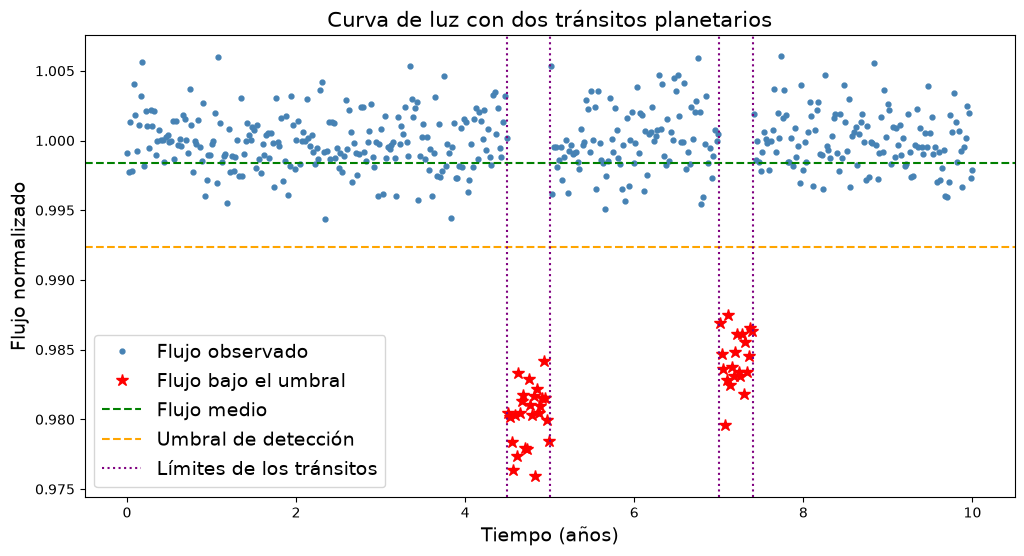

In [37]:
def graficar_curva_luz(t, flujo):
    """
    Grafica una curva de luz y destaca los puntos bajo el umbral de detección.

    Parameters
    ----------
    t : numpy.ndarray
        Arreglo con los tiempos en años.
    flujo : numpy.ndarray
        Arreglo con el flujo normalizado de la estrella.

    Returns
    -------
    None
        Muestra una figura de la curva de luz.
    """
    # Calculo el flujo medio y el umbral de detección.
    flujo_medio = np.mean(flujo)
    umbral = flujo_medio - 3 * sigma_ruido
    deteccion = flujo < umbral

    fig, ax = plt.subplots(figsize=(12, 6))

    # Muestro todos los puntos y destaco los que están bajo el umbral.
    ax.plot(t, flujo, marker='.', ls='None', color='steelblue',
            markersize=7, label='Flujo observado')
    ax.plot(t[deteccion], flujo[deteccion], marker='*', ls='None',
            color='red', markersize=9, label='Flujo bajo el umbral')

    # Marco el flujo medio y el umbral de detección.
    ax.axhline(flujo_medio, ls='--', c='green', label='Flujo medio')
    ax.axhline(umbral, ls='--', c='orange', label='Umbral de detección')

    # Marco el inicio y el término de los dos tránsitos.
    ax.axvline(4.5, ls=':', c='purple', label='Límites de los tránsitos')
    ax.axvline(5.0, ls=':', c='purple')
    ax.axvline(7.0, ls=':', c='purple')
    ax.axvline(7.4, ls=':', c='purple')

    ax.set_xlabel('Tiempo (años)', fontsize=14)
    ax.set_ylabel('Flujo normalizado', fontsize=14)
    ax.set_title('Curva de luz con dos tránsitos planetarios', fontsize=15)
    ax.legend(fontsize=14)
    plt.show()

# Ejecuto la función para visualizar la curva de luz.
graficar_curva_luz(t, flujo)

## Ejercicio 2. Imagen astronómica con cinco estrellas

En este ejercicio simularé una región del cielo que contiene cinco estrellas, utilizando funciones gaussianas bidimensionales para representar sus intensidades. También calcularé las distancias entre sus centros y analizaré cómo cambia su apariencia al modificar la dispersión espacial.

In [38]:
# Defino la cantidad de estrellas y sus parámetros.
N_estrellas = 5
I0 = 100
sigma = 0.5

# Genero las coordenadas de los centros de las cinco estrellas.
x0 = rng.uniform(-5, 5, N_estrellas)
y0 = rng.uniform(-5, 5, N_estrellas)

# Creo la cuadrícula de la región del cielo.
x = np.linspace(-6, 6, 250)
y = np.linspace(-6, 6, 250)
X, Y = np.meshgrid(x, y)


def imagen_estrellas(X, Y, x0, y0, sigma):
    """
    Calcula la intensidad total de un conjunto de estrellas gaussianas.

    Parameters
    ----------
    X, Y : numpy.ndarray
        Matrices con las coordenadas de la región.
    x0, y0 : numpy.ndarray
        Arreglos con las coordenadas centrales de las estrellas.
    sigma : int or float
        Dispersión espacial de las gaussianas.

    Returns
    -------
    numpy.ndarray
        Imagen bidimensional con la suma de las intensidades.
    """
    # La dimensión adicional permite representar las cinco estrellas.
    intensidades = I0 * np.exp(-((X[:, :, None] - x0)**2 +
                                (Y[:, :, None] - y0)**2) / (2 * sigma**2))
    imagen = np.sum(intensidades, axis=2)
    return imagen

# Calculo la imagen astronómica.
imagen = imagen_estrellas(X, Y, x0, y0, sigma)

### Imagen astronómica de cinco estrellas
En esta parte representaré una imagen de una región del cielo con cinco estrellas, utilizando las intensidades calculadas anteriormente. Agregaré una barra de color y etiquetas en ambos ejes con tamaño de fuente 14, utilizando las coordenadas x e y.

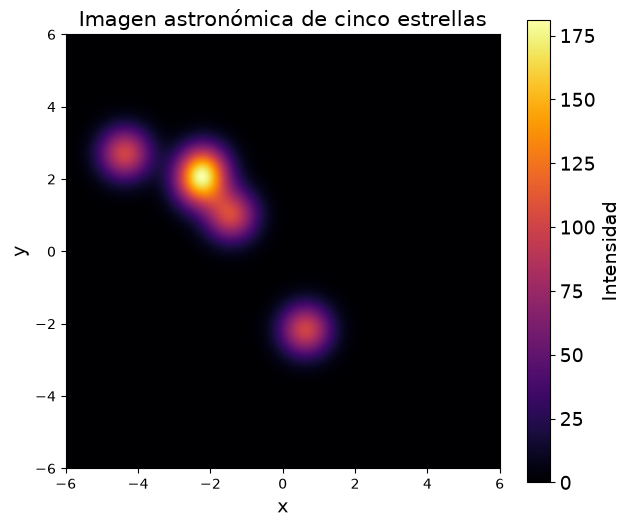

In [39]:
fig, ax = plt.subplots(figsize=(7, 6))

# Muestro la imagen y fijo los ejes en las coordenadas x e y.
im = ax.imshow(imagen, origin='lower',
               extent=[x.min(), x.max(), y.min(), y.max()], cmap='inferno')

# Agrego una barra de color con la intensidad.
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)
cbar.ax.tick_params(labelsize=14)

ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title('Imagen astronómica de cinco estrellas', fontsize=15)
plt.show()

### Distancias entre los centros de las estrellas

En esta parte calcularé las distancias entre los centros de las estrellas utilizando la fórmula de distancia euclidiana. Los resultados se organizarán en una matriz simétrica, cuya diagonal tendrá valores iguales a cero, ya que la distancia de una estrella a sí misma es cero.

In [40]:
def distancias_estrellas(x0, y0):
    """
    Calcula las distancias euclidianas entre todos los centros estelares.

    Parameters
    ----------
    x0, y0 : numpy.ndarray
        Arreglos con las coordenadas centrales de las estrellas.

    Returns
    -------
    numpy.ndarray
        Matriz de distancias entre cada par de estrellas.
    """
    # Resto las posiciones de todos los pares de centros.
    dx = x0[:, None] - x0[None, :]
    dy = y0[:, None] - y0[None, :]
    distancias = np.sqrt(dx**2 + dy**2)
    return distancias

# Obtengo la matriz de distancias entre estrellas.
distancias = distancias_estrellas(x0, y0)
distancias

array([[0.        , 0.47666308, 1.53364971, 5.32230797, 2.20978723],
       [0.47666308, 0.        , 1.22395613, 4.99228815, 2.24500689],
       [1.53364971, 1.22395613, 0.        , 3.78996003, 3.40998597],
       [5.32230797, 4.99228815, 3.78996003, 0.        , 7.00485879],
       [2.20978723, 2.24500689, 3.40998597, 7.00485879, 0.        ]])

### Imagen con estrellas numeradas según su intensidad 

En esta parte ordenaré las estrellas de menor a mayor intensidad. Como el enunciado establece $I_0=100$ para todas, sus intensidades máximas individuales son iguales. Por eso, utilizaré la intensidad total en el centro de cada estrella, considerando que puede variar debido a la superposición de sus luces. Si existen valores iguales, mantendré el orden en que se generaron los centros.

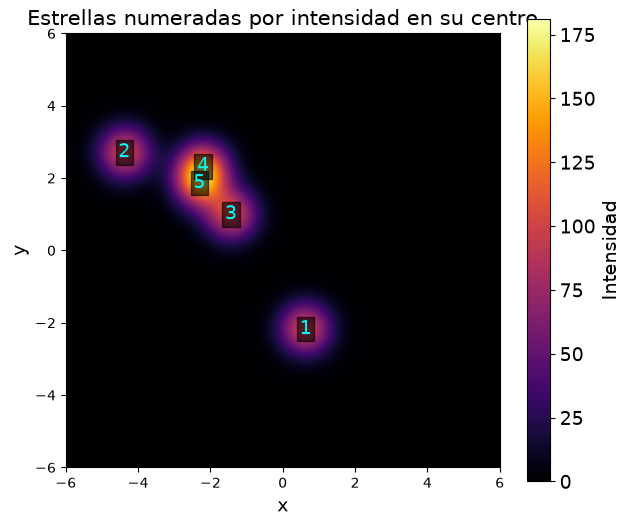

In [41]:
# Calculo la intensidad total en el centro de cada estrella.
intensidad_centros = np.sum(
    I0 * np.exp(-((x0[:, None] - x0[None, :])**2 +
                  (y0[:, None] - y0[None, :])**2) / (2 * sigma**2)),
    axis=1
)

# Ordeno los centros de menor a mayor intensidad total.
orden = np.argsort(intensidad_centros)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(imagen, origin='lower',
               extent=[x.min(), x.max(), y.min(), y.max()], cmap='inferno')

# Numero las estrellas desde 1 hasta 5, siguiendo el orden de intensidad.
for numero, indice in enumerate(orden, start=1):
    ax.text(x0[indice], y0[indice], str(numero), color='cyan',
            fontsize=14, ha='center', va='center',
            bbox={'facecolor': 'black', 'alpha': 0.6, 'pad': 2})

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Intensidad', fontsize=14)
cbar.ax.tick_params(labelsize=14)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title('Estrellas numeradas por intensidad en su centro', fontsize=15)
plt.show()

### Comparación de cuatro valores de $\sigma$

Se mantienen fijas las posiciones de las cinco estrellas y solo cambiamos la dispersión espacial. Usamos `plt.subplots` con una cuadrícula de $2\times2$, ejes compartidos y una sola barra de color para todas las imágenes.

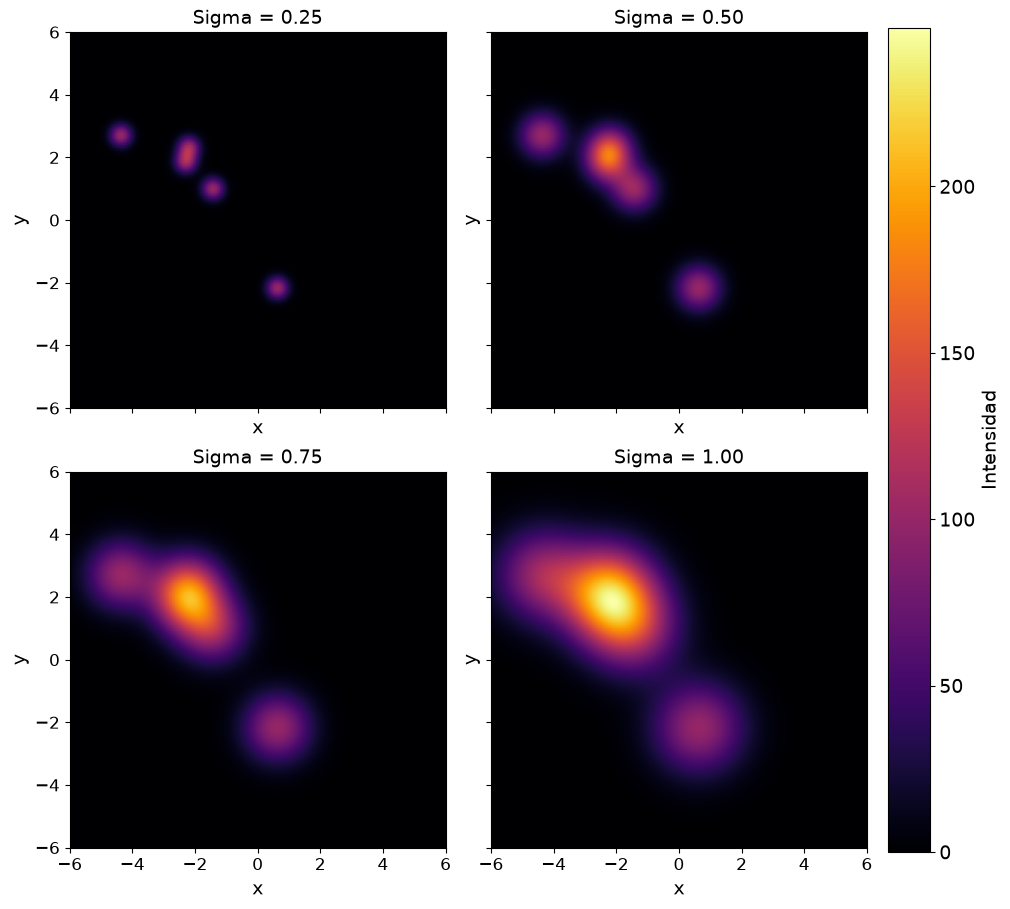

In [42]:
# Defino los cuatro valores de sigma y calculo sus imágenes.
sigmas = np.linspace(0.25, 1.0, 4)
imagenes = [imagen_estrellas(X, Y, x0, y0, s) for s in sigmas]

# Utilizo la misma escala de intensidad en las cuatro imágenes.
vmax = max(np.max(img) for img in imagenes)

fig, axs = plt.subplots(2, 2, figsize=(10, 9),
                        sharex=True, sharey=True, constrained_layout=True)

# Dibujo cada imagen en uno de los cuatro ejes.
for ax, img, s in zip(axs.flat, imagenes, sigmas):
    im = ax.imshow(img, origin='lower',
                   extent=[x.min(), x.max(), y.min(), y.max()],
                   cmap='inferno', vmin=0, vmax=vmax)
    ax.set_title(f'Sigma = {s:.2f}', fontsize=14)
    ax.set_xlabel('x', fontsize=14)
    ax.set_ylabel('y', fontsize=14)
    ax.tick_params(labelsize=12)

# Agrego una única barra de color compartida.
cbar = fig.colorbar(im, ax=axs, location='right', pad=0.02)
cbar.set_label('Intensidad', fontsize=14)
cbar.ax.tick_params(labelsize=14)
plt.show()

**Respuesta:** A medida que aumenta $\sigma$, las estrellas se ven más extendidas y difusas porque su intensidad se distribuye sobre una región mayor. Con $\sigma$ pequeño, las estrellas aparecen más concentradas. Cuando $\sigma$ aumenta, también puede crecer la superposición de sus perfiles de luz. En este modelo, la intensidad máxima individual $I_0$ se mantiene constante.